![PIC UPV PERTE Chip Chair Logo](https://www.pic-chair.upv.es/wp-content/uploads/2024/05/logo-upv-horizontal.png)
![PIC UPV PERTE Chip Chair Logo](https://www.pic-chair.upv.es/wp-content/uploads/2024/06/logos-perte-chip-1024x119.png)


# Laboratory 1. Waveguides

Welcome to our Photonic Integrated Circuits Laboratory! Throughout the course, we will be using a Python package called [GDSFactory](https://gdsfactory.github.io/gdsfactory/index.html). This is an open-source tool, and is a great alternative to other commercial software like Synopsys Optodesigner, Luceda Photonics, or Lumerical/Interconnect. Since it runs on Python, you have two options for executing your laboratory tasks:

1. **Local installation on your own PC** (Recommended): Please note that we will not spend class time on installing the software. However, feel free to reach out if you need help with the installation.

2. **Cloud Workspace**: Alternatively, you can use a cloud-based solution if the Local installation does not work.

## 0. Imports

For this laboratory you will need the following libraries:

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import tidy3d as td

import gplugins as gp
import gplugins.tidy3d as gt
from gplugins import plot
from gplugins.common.config import PATH

nm = 1e-3
wavelength = np.linspace(1500, 1600,11) * nm
f = td.C_0 / wavelength


In [2]:
nitride_complex = td.material_library["Si3N4"]["Luke2015PMLStable"].eps_model(f)
nitride_index, nitride_k = td.Medium.eps_complex_to_nk(nitride_complex)
box_complex = td.material_library["SiO2"]["Horiba"].eps_model(f)
box_index, box_k = td.Medium.eps_complex_to_nk(box_complex)

## LO.1. Effective index of a waveguide

### Convergence Tests
We have asumed until now, that the **real** value of the effective index for each cross-section is the value provided by this mode-solver. However, this number relies on a numerical method, making it sensible to some input parameters, such as the selected grid. The objective of this section is to find the dependence of the **calculated** value of the effective index with the *grid_resolution* and the *max_grid_scaling*, the two parameters that we can modify from the automatic grid function used at the gt.modes.Waveguide() function.  <br>
- Consider a 1.2 um width deep waveguide (SiNx), with 0.3 um height operating at 1550 nm.
    - Sweep the *grid_resolution* between 10 and 100 in steps of 10. Plot the **calculated** effective index vs the *grid_resolution*. 
    - Select a value for the *grid_resolution* from the latter sweep (where the calculated index remains almost constant), and sweep the *max_grid_scaling* from 1.2 to 1.6 in steps of 0.1. Plot the **calculated** effective index vs the *max_grid_scaling*.
    - Conclude which will be the best configuration for the grid parameters for this particular case. 

In [ ]:
grid_resolution = np.linspace(10,100,10)
max_grid_scaling = np.linspace(1.2,1.6,5)

n_eff = []
fraction_te = []

In [35]:
for grid_res in grid_resolution:
    deep_waveguide = gt.modes.Waveguide(
        # Geometrical Parameters
        core_width=1.2, # Waveguide width
        core_thickness=300 * nm, # Waveguide height 
        slab_thickness=0 * nm, # For shallow waveguides - Set to 0 if its a deep-etched waveguide.
        # Materials
        core_material='sin', #  Material of the waveguide
        clad_material='sio2', # Surrounding material
        # Modesolver Parameters
        wavelength=1550 * nm, # Wavelength to simulate
        num_modes=4, # Targeted number of modes to find 
        max_grid_scaling=1.5, # Parameters of the grid 
        grid_resolution=grid_res, # Parameters of the grid
        cache_path='.cache/', # Important! In order to save simulation time, set your cache Path!
        precision='double',
    )

    #deep_waveguide.plot_index()
    n_eff.append(deep_waveguide.n_eff)
    fraction_te.append(deep_waveguide.fraction_te)

2026-10-30 09:45:30.988 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_13fe960528db7e9b.npz.
2026-10-30 09:45:30.998 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_cf92515ae4232c65.npz.
2026-10-30 09:45:31.006 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_152975b7cd7bd92b.npz.
2026-10-30 09:45:31.014 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_721700b7522a7617.npz.
2026-10-30 09:45:31.020 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_0ea6c3bb3b1c00e8.npz.
2026-10-30 09:45:31.069 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_67a04e2475ce3436.npz.
2026-10-30 09:45:31.116 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_b110164ae7f9a70a.npz.
2026-10-30 09:45:31.175 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_c8d8b6bf9be8a3e8.npz.


In [20]:
fraction_te

[array([0.99474718, 0.00926039, 0.968749  , 0.0480113 ]),
 array([0.99505426, 0.01004259, 0.96264794, 0.047651  ]),
 array([0.99575806, 0.00918099, 0.96351813, 0.04146956]),
 array([0.99589059, 0.00872346, 0.96181774, 0.04150954]),
 array([0.99601247, 0.00853277, 0.95991595, 0.04265049]),
 array([0.99631531, 0.00807737, 0.95990672, 0.04206394]),
 array([0.99653994, 0.00766236, 0.95932394, 0.04098711]),
 array([0.99651728, 0.00757823, 0.95900442, 0.04126066]),
 array([0.99674561, 0.00732726, 0.95931703, 0.04065949]),
 array([0.99693292, 0.00705645, 0.95942541, 0.04044323])]

In [ ]:
n_eff_TE0 = []
for i in range(len(n_eff)):
    n_eff_TE0.append(n_eff[i][0].real)

C:\Users\cfp\AppData\Local\Temp\ipykernel_12964\1637776511.py:11: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(loc='upper left', bbox_to_anchor=(1, 1))


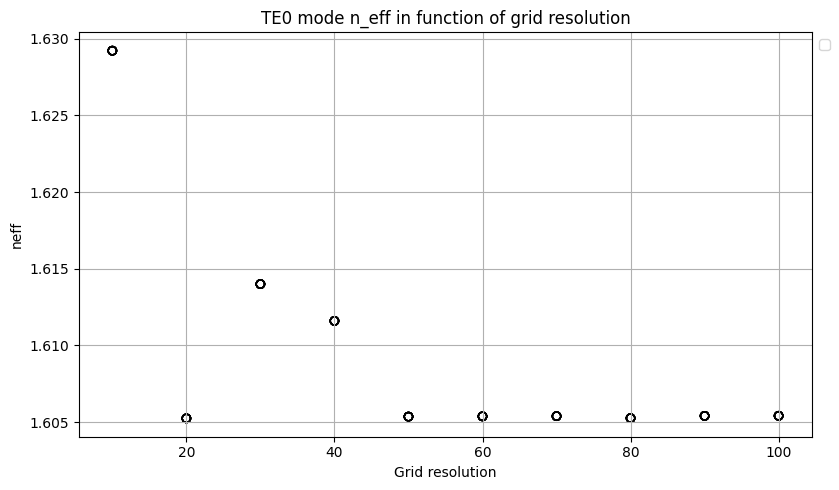

In [34]:
plt.figure(figsize=(10, 5))
for k in range(len(grid_resolution)):
    # It's necessary to 'access' each element on the array
    plt.scatter(grid_resolution, n_eff_TE0,edgecolors='k',facecolors='none',label = '__nolegend__')
    #plt.plot(grid_resolution, n_eff_TE0,label=f'Mode {k}')
plt.title(f"TE0 mode n_eff in function of grid resolution")
plt.xlabel("Grid resolution")
plt.ylabel("neff")
plt.grid()
#plt.plot(grid_resolution, box_index,'k--', label='SiO2 index')
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout(rect=[0, 0, 0.85, 1])

Entiendo que a partir de 50 el neff converge a un valor más o menos estable. Por lo que decido usar el valor 20, el mínimo que me da esa estabilidad

In [42]:
n_eff = []
fraction_te = []
for max_grid in max_grid_scaling:
    deep_waveguide = gt.modes.Waveguide(
        # Geometrical Parameters
        core_width=1.2, # Waveguide width
        core_thickness=300 * nm, # Waveguide height 
        slab_thickness=0 * nm, # For shallow waveguides - Set to 0 if its a deep-etched waveguide.
        # Materials
        core_material='sin', #  Material of the waveguide
        clad_material='sio2', # Surrounding material
        # Modesolver Parameters
        wavelength=1550 * nm, # Wavelength to simulate
        num_modes=4, # Targeted number of modes to find 
        max_grid_scaling=max_grid, # Parameters of the grid 
        grid_resolution=20, # Parameters of the grid
        cache_path='.cache/', # Important! In order to save simulation time, set your cache Path!
        precision='double',
    )

    #deep_waveguide.plot_index()
    n_eff.append(deep_waveguide.n_eff)
    fraction_te.append(deep_waveguide.fraction_te)

2026-10-30 09:52:52.327 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_29761b037c0c9026.npz.
2026-10-30 09:52:52.342 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_3312bd34c8e3dc78.npz.
2026-10-30 09:52:52.360 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_3a47af964cab67f8.npz.
2026-10-30 09:52:52.376 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_d822c60cf88b209f.npz.
2026-10-30 09:52:52.389 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_b169dc1f7a2c6666.npz.
2026-10-30 09:52:52.411 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_683206c3f01233c4.npz.


In [43]:
n_eff_TE0 = []
for i in range(len(n_eff)):
    n_eff_TE0.append(n_eff[i][0].real)

C:\Users\cfp\AppData\Local\Temp\ipykernel_12964\3844750142.py:11: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(loc='upper left', bbox_to_anchor=(1, 1))


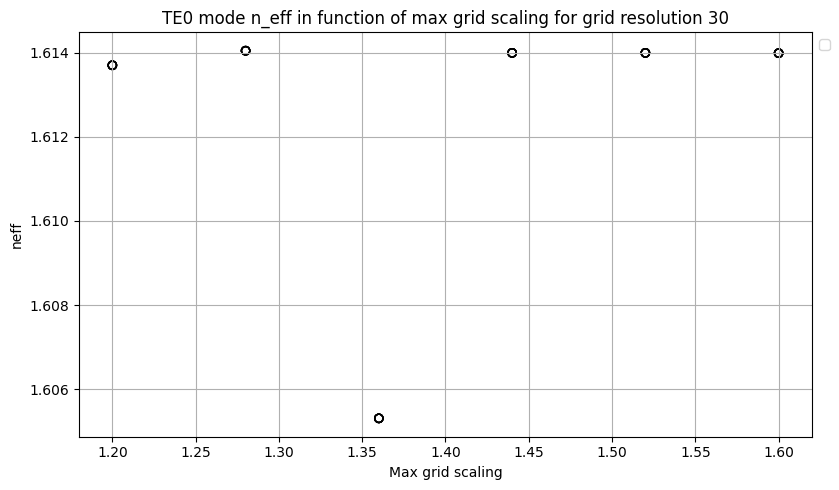

In [ ]:
plt.figure(figsize=(10, 5))
for k in range(len(max_grid_scaling)):
    # It's necessary to 'access' each element on the array
    plt.scatter(max_grid_scaling, n_eff_TE0,edgecolors='k',facecolors='none',label = '__nolegend__')
    #plt.plot(max_grid_scaling, n_eff_TE0,label=f'Mode {k}')
plt.title(f"TE0 mode n_eff in function of max grid scaling for grid resolution 30")
plt.xlabel("Max grid scaling")
plt.ylabel("neff")
plt.grid()
#plt.plot(grid_resolution, box_index,'k--', label='SiO2 index')
#plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout(rect=[0, 0, 0.85, 1])

Esto es con un grid que no converge, 30. Me dice que este grid no converge excepto un valor de grid scalin concreto, muy sensible al error. Aquí se ve la importancia de hacer fine tuning de lo sparámetros. Determinará la robustez de tus resultados

C:\Users\cfp\AppData\Local\Temp\ipykernel_12964\1334806636.py:11: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(loc='upper left', bbox_to_anchor=(1, 1))


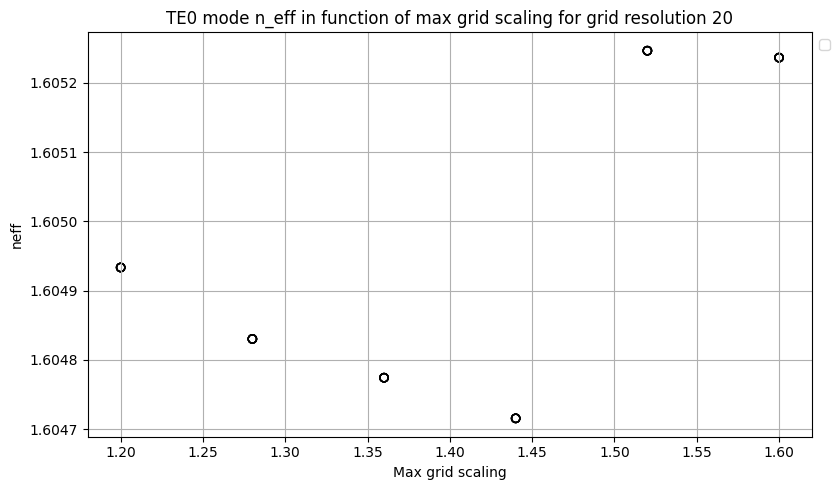

In [45]:
plt.figure(figsize=(10, 5))
for k in range(len(max_grid_scaling)):
    # It's necessary to 'access' each element on the array
    plt.scatter(max_grid_scaling, n_eff_TE0,edgecolors='k',facecolors='none',label = '__nolegend__')
    #plt.plot(max_grid_scaling, n_eff_TE0,label=f'Mode {k}')
plt.title(f"TE0 mode n_eff in function of max grid scaling for grid resolution 20")
plt.xlabel("Max grid scaling")
plt.ylabel("neff")
plt.grid()
#plt.plot(grid_resolution, box_index,'k--', label='SiO2 index')
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout(rect=[0, 0, 0.85, 1])

El tiempo de ejecución entre 1.2 y 1.4 max scalling no es muy grande, puedo coger 1.4 que parece más cercano al valor convergente. Se obsera que 1.5 y 1.6 ya divergen del neff óptimo

## LO.2. Width dependence

- Perform a sweep of the **deep** waveguide width. Use the code provided in the following cell or program your own sweep. 

  0%|          | 0/11 [00:00<?, ?it/s]

2026-10-30 10:06:41.879 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_a1188177df9d4412.npz.
2026-10-30 10:06:41.894 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_eaf8803b7dd0ab21.npz.
2026-10-30 10:06:41.900 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_d65d3bf0b50545c0.npz.
2026-10-30 10:06:41.900 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_10f7023e62ba3f62.npz.
2026-10-30 10:06:41.926 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_92d005b8bcbdcd88.npz.
2026-10-30 10:06:41.936 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_fd3ef6feb17ea835.npz.
2026-10-30 10:06:41.945 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_3fc9fcf961f2ad42.npz.
2026-10-30 10:06:41.952 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_2936a0a7e236aac8.npz.


  0%|          | 0/11 [00:00<?, ?it/s]

2026-10-30 10:06:41.988 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_a1188177df9d4412.npz.
2026-10-30 10:06:41.997 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_eaf8803b7dd0ab21.npz.
2026-10-30 10:06:41.998 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_d65d3bf0b50545c0.npz.
2026-10-30 10:06:41.998 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_10f7023e62ba3f62.npz.
2026-10-30 10:06:42.016 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_92d005b8bcbdcd88.npz.
2026-10-30 10:06:42.022 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_fd3ef6feb17ea835.npz.
2026-10-30 10:06:42.029 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_3fc9fcf961f2ad42.npz.
2026-10-30 10:06:42.035 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_2936a0a7e236aac8.npz.


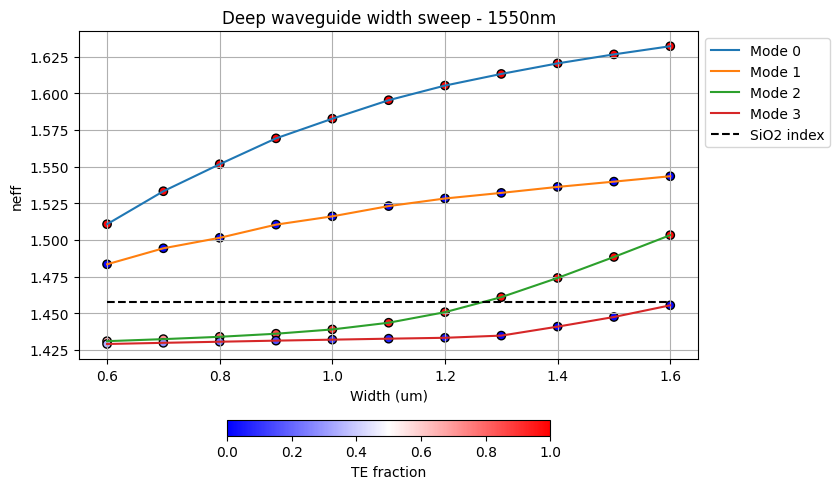

In [ ]:
wavelength = 1550 * nm # Student code here

deep_waveguide = gt.modes.Waveguide(
    wavelength=wavelength,
    core_width=1.2,
    core_material='sin',
    clad_material='sio2',
    core_thickness=300 * nm,
    slab_thickness=0 * nm,
    num_modes=4,
    cache_path='.cache/',
    precision='double',
    max_grid_scaling=1.4,
    grid_resolution=20, 
)

w = np.linspace(0.6,1.6,11) # Student code here

sweep_neff = gt.modes.sweep_n_eff(deep_waveguide, 
                             core_width=w)

sweep_tefraction = gt.modes.sweep_fraction_te(deep_waveguide,
                                              core_width=w)

plt.figure(figsize=(10, 5))
for k in range(sweep_neff.shape[1]):
    plt.scatter(w, sweep_neff[:,k].real,edgecolors='k',c=sweep_tefraction.sel(mode_index=k),vmin=0, vmax=1,label = '__nolegend__',cmap='bwr')
    plt.plot(w, sweep_neff[:,k].real,label=f'Mode {k}')

plt.title("Deep waveguide width sweep - 1550nm")
plt.xlabel("Width (μm)")
plt.ylabel("neff")
plt.grid()
plt.hlines(np.mean(box_index), xmin=np.min(w), xmax=np.max(w), colors='k', linestyles='dashed',label='SiO2 index')
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout(rect=[0, 0, 0.85, 1])
plt.colorbar(orientation='horizontal',fraction=0.04).set_label("TE fraction")

Se ve claramente como los modos 2, solo empiezan a poder se guiados a partir de width = 1.3 micras. Por otor lado, el modo 3, que se trata de un modo TM, no puede ser guiado en esta guia de onda dado esta diferencia de índice, thickness y longitud de onda. Es decir, para la polarización TM la guía, en este rango de width es monomodo. Sin embargo, a aprtir de 1.2/1.3 para TE la guía empezará a poder guiar un segundo modo.

## LO.3. Waveguide compact model

A compact model of an integrated photonic waveguide is a reduced-order mathematical model that describes the waveguide’s optical behavior—such as phase propagation, loss, and dispersion, using analytical or semi-analytical equations. Consider: 

Transfer function for propagation in a waveguide:

$$
H(\lambda)
= e^{-j\,\beta(\lambda)\,z}
= e^{-j\,\mathrm{Re}\{\beta(\lambda)\}\,z}\,
  e^{\mathrm{Im}\{\beta(\lambda)\}\,z}.
$$

Where 

$$
\beta(\lambda)
= \frac{2\pi}{\lambda}\,\mathrm{Re}\{n_\mathrm{eff}(\lambda)\}.
$$

Let's model the waveguide's effective index wavelength variation using a second order polynomial:

$$
n_\mathrm{eff}(\lambda)
= n_{1} + n_{2}\,(\lambda-\lambda_{0}) + n_{3}\,(\lambda-\lambda_{0})^{2}
$$

Where 

1. 
$$
n_\mathrm{eff}(\lambda_0) = n_1
$$
2. 
$$
n_g(\lambda_0) = n_1 - n_2\,\lambda_0
$$
3. 
$$
D = -\frac{2\,\lambda_0\,n_3}{c}\;\;[\mathrm{s}^2/\mathrm{m}]
$$

- Find the **compact models** of the following waveguides: 
    - Deep waveguide, height = 300nm, width = 1.2um 
    - Shallow waveguide, core height = 300nm, slab height = 150 nm, width = 1.2um 

**TIP**. Use the Lab0.1.Modesolver results (neff vs lambda) as starting point. Fit the results using a second order polynomial (with the lambda_0 shift) and relate the fit results to n_g and D values.

### Deep waveguide

2026-10-30 11:54:43.949 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_453210b0140a829a.npz.


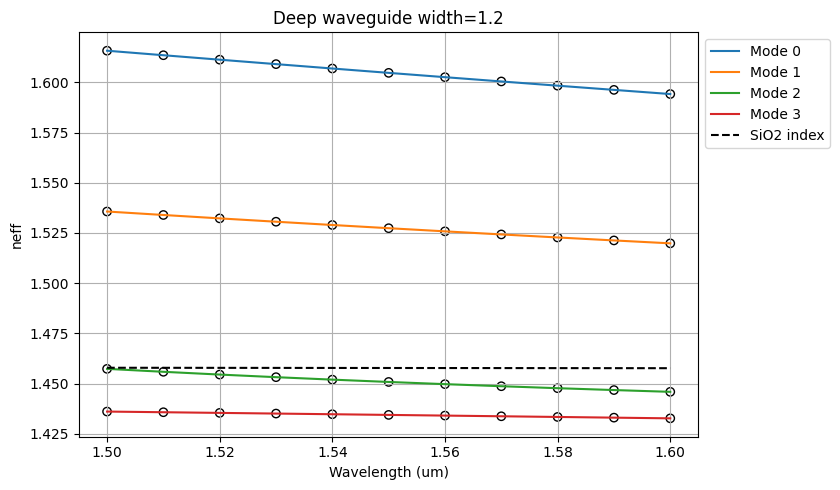

In [ ]:
# The wavelength could be a vector also
wavelength = np.linspace(1500, 1600,11) * nm

deep_waveguide = gt.modes.Waveguide(
    wavelength=wavelength, 
    core_width=1.2, 
    slab_thickness=0.0,
    core_material='sin',
    clad_material='sio2',
    core_thickness=300 * nm,
    num_modes=4,
    cache_path='.cache/',
    precision='double',
    max_grid_scaling=1.4,
    grid_resolution=20, 
)

res_neff = deep_waveguide.n_eff # In this case, the result is not just a number, is a wavelength-dependent vector
res_te = deep_waveguide.fraction_te # Wavelength-dependent vector
res_tm =deep_waveguide.fraction_tm # Wavelength-dependent vector

plt.figure(figsize=(10, 5))
for k in range(res_neff.shape[1]):
    # It's necessary to 'access' each element on the array
    plt.scatter(wavelength, res_neff[:,k].real,edgecolors='k',facecolors='none',label = '__nolegend__')
    plt.plot(wavelength, res_neff[:,k].real,label=f'Mode {k}')
plt.title(f"Deep waveguide width={1.2}")
plt.xlabel("Wavelength (μm)")
plt.ylabel("neff")
plt.grid()
plt.plot(wavelength, box_index,'k--', label='SiO2 index')
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout(rect=[0, 0, 0.85, 1])

As we see, beff with lambda follows a linear dependency. We do a second order linear fit for the two modes that are guided (TE0 and TM0). We have to take in account that the fit is done centered to a lamda_0. So I have to shift the values

In [174]:
lambda_0 = 1550
wavelength = wavelength = np.linspace(1500, 1600,11) 
wavelength = wavelength -1550
wavelength = wavelength * nm
print(wavelength)

[-0.05 -0.04 -0.03 -0.02 -0.01  0.    0.01  0.02  0.03  0.04  0.05]


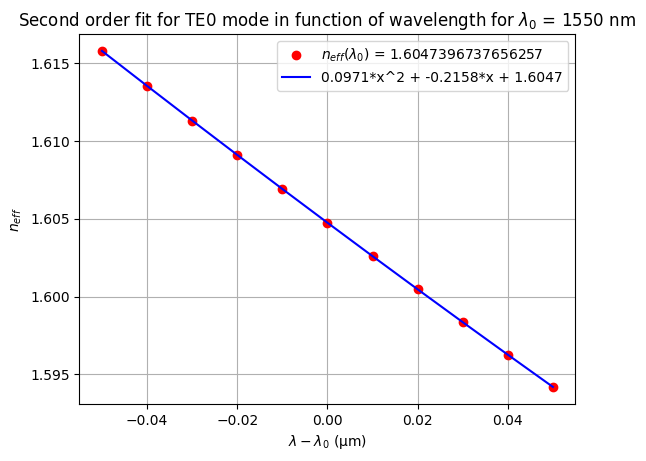

In [234]:
# Ajuste a segundo orden 
lambda_0_latex = r'\lambda_0'
neff_latex = r'n_{eff}'
plt.plot(wavelength,res_neff[:,0].real,'ro',label=f'${neff_latex}$(${lambda_0_latex}$) = {res_neff[5,0].real}')

p = np.polyfit(wavelength,res_neff[:,0].real,2)
plt.plot(wavelength,np.polyval(p, wavelength),color='blue',label=f'{round(p[0], 4)}*x^2 + {round(p[1], 4)}*x + {round(p[2], 4)}')
lambda_0_latex = r'\lambda_0'
plt.title(f"Second order fit for TE0 mode in function of wavelength for ${lambda_0_latex}$ = 1550 nm")
latex = r'\lambda-\lambda_0'
plt.xlabel(f'${latex}$ (μm)')
neff_latex = r'n_{eff}'
plt.ylabel(f'${neff_latex}$')
plt.grid()
plt.legend()
plt.show()

In [235]:
print(res_neff[5,0].real)
print(p)
ng_TE0 = p[2]-p[1]*lambda_0*nm
D = -2*lambda_0*nm*p[0]/(3*10**14) #La velocidad en micras por segundo!
print(f"neff_TE0_deep = {p[2]}")
print(f"ng_TE0_deep= {ng_TE0}")
print(f"D_TE0_deep = {D}")

1.6047396737656257
[ 0.09710981 -0.2157782   1.60473968]
neff_TE0_deep = 1.6047396802144442
ng_TE0_deep= 1.9391958912786222
D_TE0_deep = -1.003468007111464e-15


La ordenada es el neff de la longitud de onda central que hemos cogido! Vamos con el TM

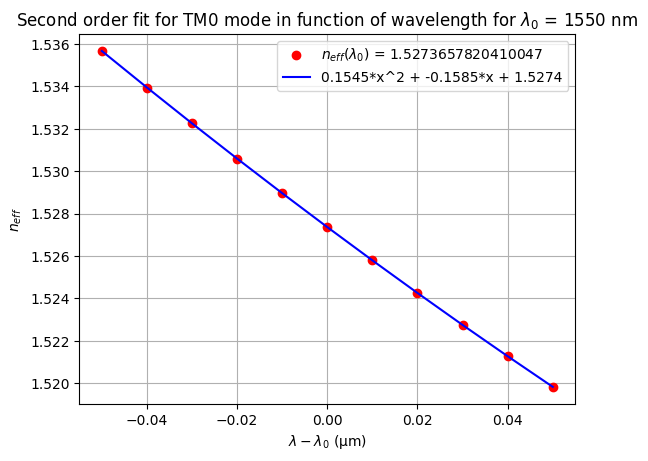

In [236]:
# Ajuste a segundo orden 
lambda_0_latex = r'\lambda_0'
neff_latex = r'n_{eff}'
plt.plot(wavelength,res_neff[:,1].real,'ro',label=f'${neff_latex}$(${lambda_0_latex}$) = {res_neff[5,1].real}')

p_TM = np.polyfit(wavelength,res_neff[:,1].real,2)
plt.plot(wavelength,np.polyval(p_TM, wavelength),color='blue',label=f'{round(p_TM[0], 4)}*x^2 + {round(p_TM[1], 4)}*x + {round(p_TM[2], 4)}')
lambda_0_latex = r'\lambda_0'
plt.title(f"Second order fit for TM0 mode in function of wavelength for ${lambda_0_latex}$ = 1550 nm")
plt.xlabel(f'${latex}$ (μm)')
plt.ylabel(f'${neff_latex}$')
plt.grid()
plt.legend()
plt.show()

In [237]:
print(res_neff[5,1].real)
print(p_TM)
ng_TM0 = p_TM[2]-p_TM[1]*lambda_0*nm
D = -2*lambda_0*nm*p_TM[0]/(3*10**14) #La velocidad en micras por segundo!
print(f"neff_TM0_deep = {p_TM[2]}")
print(f"ng_TM0_deep= {ng_TM0}")
print(f"D_TM0_deep = {D}")

1.5273657820410047
[ 0.15449925 -0.15846764  1.52736578]
neff_TM0_deep = 1.527365783362299
ng_TM0_deep= 1.7729906232169064
D_TM0_deep = -1.5964922734082534e-15


### Shallow waveguide

#### Convergence Tests

Vamos ahora con la shallow, empecemos con el análisis de convergencia

In [197]:
grid_resolution = np.linspace(10,100,10)
max_grid_scaling = np.linspace(1.2,1.6,5)

n_eff = []
fraction_te = []

In [198]:
for grid_res in grid_resolution:
    deep_waveguide = gt.modes.Waveguide(
        # Geometrical Parameters
        core_width=1.2, # Waveguide width
        core_thickness=300 * nm, # Waveguide height 
        slab_thickness=150 * nm, # For shallow waveguides - Set to 0 if its a deep-etched waveguide.
        # Materials
        core_material='sin', #  Material of the waveguide
        clad_material='sio2', # Surrounding material
        # Modesolver Parameters
        wavelength=1550 * nm, # Wavelength to simulate
        num_modes=4, # Targeted number of modes to find 
        max_grid_scaling=1.5, # Parameters of the grid 
        grid_resolution=grid_res, # Parameters of the grid
        cache_path='.cache/', # Important! In order to save simulation time, set your cache Path!
        precision='double',
    )

    #deep_waveguide.plot_index()
    n_eff.append(deep_waveguide.n_eff)
    fraction_te.append(deep_waveguide.fraction_te)

2026-10-30 13:03:34.602 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_50a2081fb4ed77b7.npz.
2026-10-30 13:03:34.602 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_1982ab1e607e2389.npz.
2026-10-30 13:03:34.616 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_5ce4684c98b1c5a0.npz.
2026-10-30 13:03:34.616 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_c9345f91df072783.npz.
2026-10-30 13:03:34.636 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_ea27531f8477b92f.npz.
2026-10-30 13:03:34.641 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_fd3d2890d3696fd6.npz.
2026-10-30 13:03:34.649 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_ea4235cd69c1f318.npz.
2026-10-30 13:03:34.650 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_4b81dc55c47e869a.npz.


In [199]:
fraction_te

[array([0.99777278, 0.90101209, 0.04070159, 0.99995503]),
 array([0.99689796, 0.2230249 , 0.66053185, 0.99998122]),
 array([0.9973071 , 0.96832155, 0.99998826, 0.02170691]),
 array([0.99708454, 0.86386199, 0.07384484, 0.99997185]),
 array([0.99713576, 0.63870293, 0.22395715, 0.99998801]),
 array([0.9973805 , 0.87702858, 0.06731084, 0.99998889]),
 array([0.99749056, 0.87271681, 0.06988123, 0.99998975]),
 array([0.99747389, 0.87352247, 0.07023829, 0.99999292]),
 array([0.99760112, 0.86701293, 0.07392926, 0.99999061]),
 array([0.99764496, 0.85388892, 0.08311267, 0.99998701])]

In [ ]:
n_eff_TE0 = []
for i in range(len(n_eff)):
    n_eff_TE0.append(n_eff[i][0].real)
print(range(len(n_eff_TE0)), range(len(grid_resolution)))

range(0, 10) range(0, 10)


C:\Users\cfp\AppData\Local\Temp\ipykernel_12964\1637776511.py:11: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(loc='upper left', bbox_to_anchor=(1, 1))


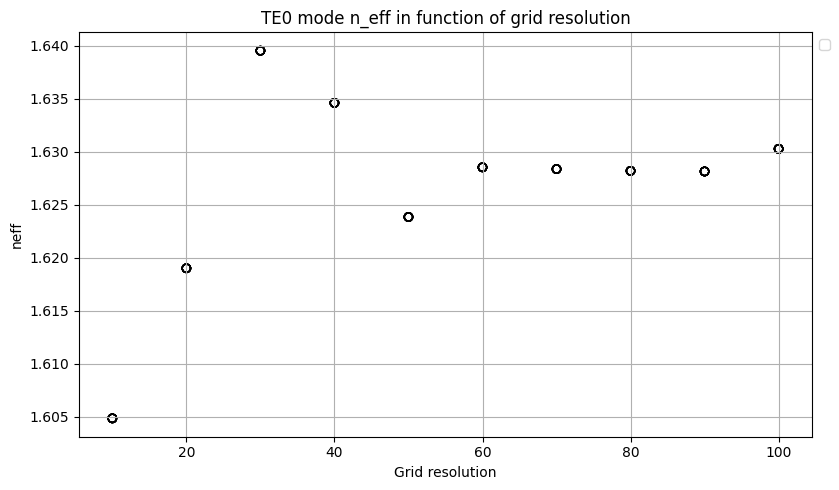

In [204]:
plt.figure(figsize=(10, 5))
for k in range(len(grid_resolution)):
    # It's necessary to 'access' each element on the array
    plt.scatter(grid_resolution, n_eff_TE0,edgecolors='k',facecolors='none',label = '__nolegend__')
    #plt.plot(grid_resolution, n_eff_TE0,label=f'Mode {k}')
plt.title(f"TE0 mode n_eff in function of grid resolution")
plt.xlabel("Grid resolution")
plt.ylabel("neff")
plt.grid()
#plt.plot(grid_resolution, box_index,'k--', label='SiO2 index')
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout(rect=[0, 0, 0.85, 1])

En este caso 20 no parece un buen valor, escojo 60, el mínimo grid resolution que parece haber convergido

In [212]:
n_eff = []
fraction_te = []
for max_grid in max_grid_scaling:
    deep_waveguide = gt.modes.Waveguide(
        # Geometrical Parameters
        core_width=1.2, # Waveguide width
        core_thickness=300 * nm, # Waveguide height 
        slab_thickness=150 * nm, # For shallow waveguides - Set to 0 if its a deep-etched waveguide.
        # Materials
        core_material='sin', #  Material of the waveguide
        clad_material='sio2', # Surrounding material
        # Modesolver Parameters
        wavelength=1550 * nm, # Wavelength to simulate
        num_modes=4, # Targeted number of modes to find 
        max_grid_scaling=max_grid, # Parameters of the grid 
        grid_resolution=60, # Parameters of the grid
        cache_path='.cache/', # Important! In order to save simulation time, set your cache Path!
        precision='double',
    )

    #deep_waveguide.plot_index()
    n_eff.append(deep_waveguide.n_eff)
    fraction_te.append(deep_waveguide.fraction_te)

2026-10-30 13:14:13.438 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_0acdaa8abc194b41.npz.
2026-10-30 13:14:13.470 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_723fe335f4c36746.npz.
2026-10-30 13:14:13.489 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_440ac1118da055c4.npz.
2026-10-30 13:14:13.506 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_fd3d2890d3696fd6.npz.
2026-10-30 13:14:13.512 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_99f87009edfe858e.npz.


In [213]:
fraction_te

[array([0.99732742, 0.87237531, 0.06881998, 0.99998824]),
 array([0.99743283, 0.94910932, 0.02928777, 0.9999952 ]),
 array([0.99744613, 0.87186978, 0.06958166, 0.99998895]),
 array([0.9973805 , 0.87702858, 0.06731084, 0.99998889]),
 array([0.99736695, 0.87695733, 0.06731407, 0.99998886])]

In [214]:
n_eff_TE0 = []
for i in range(len(n_eff)):
    n_eff_TE0.append(n_eff[i][0].real)
print(range(len(n_eff_TE0)), range(len(max_grid_scaling)))

range(0, 5) range(0, 5)


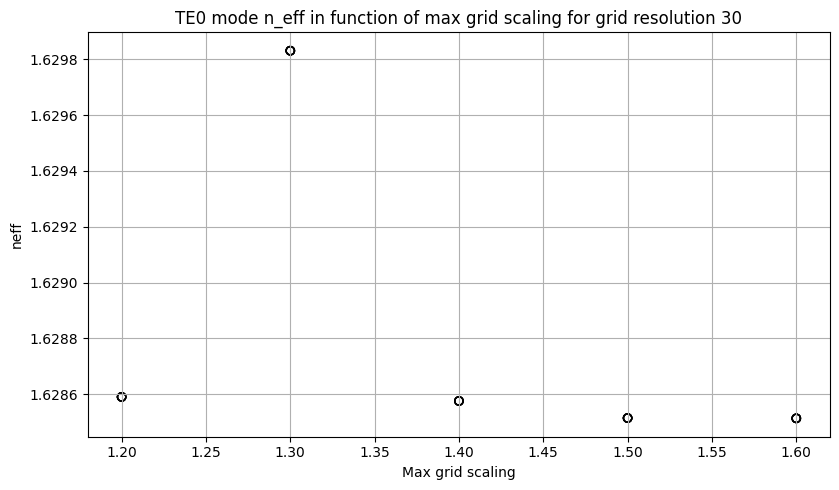

In [215]:
plt.figure(figsize=(10, 5))
for k in range(len(max_grid_scaling)):
    # It's necessary to 'access' each element on the array
    plt.scatter(max_grid_scaling, n_eff_TE0,edgecolors='k',facecolors='none',label = '__nolegend__')
    #plt.plot(max_grid_scaling, n_eff_TE0,label=f'Mode {k}')
plt.title(f"TE0 mode n_eff in function of max grid scaling for grid resolution 30")
plt.xlabel("Max grid scaling")
plt.ylabel("neff")
plt.grid()
#plt.plot(grid_resolution, box_index,'k--', label='SiO2 index')
#plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout(rect=[0, 0, 0.85, 1])

Vemos que a partir de 1.4 se obtiene una solución convergente. Escojo 1.4 como el caso anterior y para no subir mucho tiempo computación. Pero en este caso el primer modo TM es el tercer modo. Se sospecha que no va muy bien este mode solver, queda pendiente revisarlo con otra librería. Uso para el shallow mismos parámetros grid que el caso deep

#### Compact model

2026-10-30 13:27:40.261 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_7ffbb4c2e95aaca4.npz.


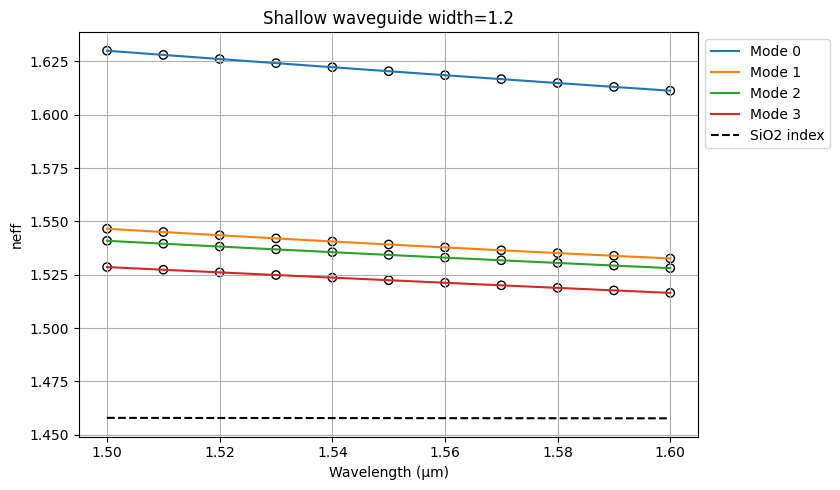

In [233]:
# The wavelength could be a vector also
wavelength_array = np.linspace(1500, 1600,11) * nm

shallow_waveguide = gt.modes.Waveguide(
    wavelength=wavelength_array, 
    core_width=1.2, 
    slab_thickness=150*nm,
    core_material='sin',
    clad_material='sio2',
    core_thickness=300 * nm,
    num_modes=4,
    cache_path='.cache/',
    precision='double',
    max_grid_scaling=1.4,
    grid_resolution=20, 
)

res_neff_shallow = shallow_waveguide.n_eff # In this case, the result is not just a number, is a wavelength-dependent vector
res_te_shallow = shallow_waveguide.fraction_te # Wavelength-dependent vector
res_tm_shallow =shallow_waveguide.fraction_tm # Wavelength-dependent vector

plt.figure(figsize=(10, 5))
for k in range(res_neff_shallow.shape[1]):
    # It's necessary to 'access' each element on the array
    plt.scatter(wavelength_array, res_neff_shallow[:,k].real,edgecolors='k',facecolors='none',label = '__nolegend__')
    plt.plot(wavelength_array, res_neff_shallow[:,k].real,label=f'Mode {k}')
plt.title(f"Shallow waveguide width={1.2}")
plt.xlabel("Wavelength (μm)")
plt.ylabel("neff")
plt.grid()
plt.plot(wavelength_array, box_index,'k--', label='SiO2 index')
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout(rect=[0, 0, 0.85, 1])

In [190]:
print(res_te_shallow)
print(res_tm_shallow)

[0.99686049 0.3869831  0.45593755 0.99999304]
[3.13950886e-03 6.13016897e-01 5.44062445e-01 6.95526976e-06]


El primer cambio es que ahora guio los 4 modos! Y el otro cambio es que no tengo modos TM, solo híbridos. Analizaré el segundo modo que me sale que es el primer modo híbrido

In [216]:
lambda_0 = 1550
wavelength = wavelength = np.linspace(1500, 1600,11) 
wavelength = wavelength -1550
wavelength = wavelength * nm
print(wavelength)

[-0.05 -0.04 -0.03 -0.02 -0.01  0.    0.01  0.02  0.03  0.04  0.05]


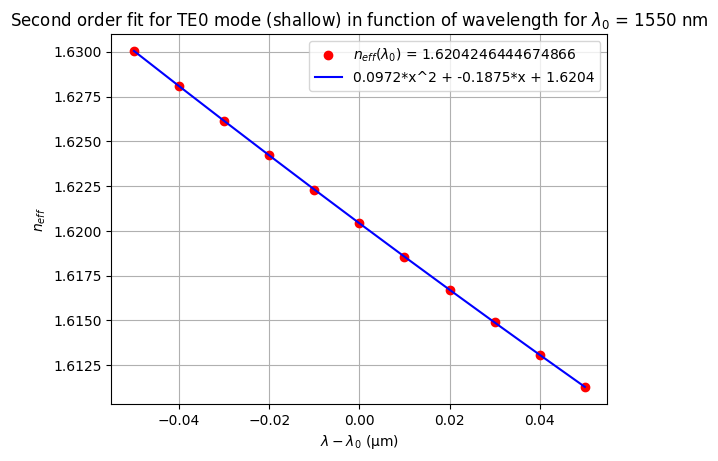

In [232]:
# Ajuste a segundo orden 
lambda_0_latex = r'\lambda_0'
neff_latex = r'n_{eff}'
plt.plot(wavelength,res_neff_shallow[:,0].real,'ro',label=f'${neff_latex}$(${lambda_0_latex}$) = {res_neff_shallow[5,0].real}')

p_TE = np.polyfit(wavelength,res_neff_shallow[:,0].real,2)
plt.plot(wavelength,np.polyval(p_TE, wavelength),color='blue',label=f'{round(p_TE[0], 4)}*x^2 + {round(p_TE[1], 4)}*x + {round(p_TE[2], 4)}')
lambda_0_latex = r'\lambda_0'
plt.title(f"Second order fit for TE0 mode (shallow) in function of wavelength for ${lambda_0_latex}$ = 1550 nm")
latex = r'\lambda-\lambda_0'
plt.xlabel(f'${latex}$ (μm)')
neff_latex = r'n_{eff}'
plt.ylabel(f'${neff_latex}$')
plt.grid()
plt.legend()
plt.show()

In [218]:
print(res_neff_shallow[5,0].real)
print(p_TE)
ng_TE0 = p_TE[2]-p_TE[1]*lambda_0*nm
D = -2*lambda_0*nm*p_TE[0]/(3*10**14) #La velocidad en micras por segundo!
print(f"neff_TE0_shallow = {p_TE[2]}")
print(f"ng_TE0_shallow= {ng_TE0}")
print(f"D_TE0_shallow = {D}")

1.6204246444674866
[ 0.0971754  -0.18751823  1.62042465]
neff_TE0_shallow = 1.6204246472537587
ng_TE0_shallow= 1.9110778980708836
D_TE0_shallow = -1.0041458132858068e-15


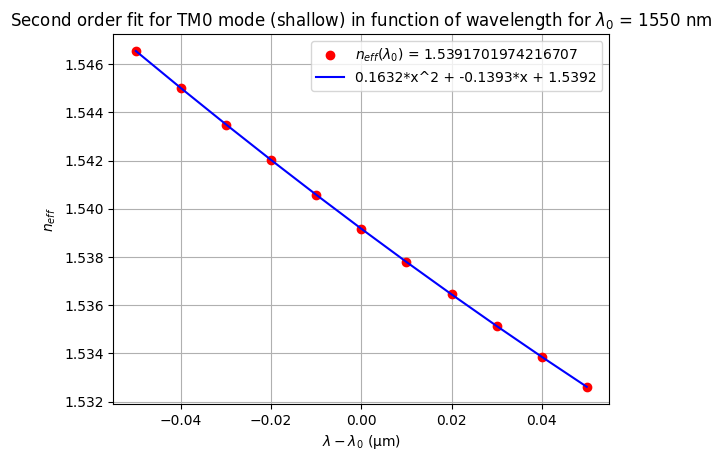

In [230]:
# Ajuste a segundo orden 
lambda_0_latex = r'\lambda_0'
neff_latex = r'n_{eff}'
plt.plot(wavelength,res_neff_shallow[:,1].real,'ro',label=f'${neff_latex}$(${lambda_0_latex}$) = {res_neff_shallow[5,1].real}')

p_TM = np.polyfit(wavelength,res_neff_shallow[:,1].real,2)
plt.plot(wavelength,np.polyval(p_TM, wavelength),color='blue',label=f'{round(p_TM[0], 4)}*x^2 + {round(p_TM[1], 4)}*x + {round(p_TM[2], 4)}')
lambda_0_latex = r'\lambda_0'
plt.title(f"Second order fit for TM0 mode (shallow) in function of wavelength for ${lambda_0_latex}$ = 1550 nm")
latex = r'\lambda-\lambda_0'
plt.xlabel(f'${latex}$ (μm)')
neff_latex = r'n_{eff}'
plt.ylabel(f'${neff_latex}$')
plt.grid()
plt.legend()
plt.show()

In [231]:
print(res_neff_shallow[5,1].real)
print(p_TM)
ng_TM0 = p_TM[2]-p_TM[1]*lambda_0*nm
D = -2*lambda_0*nm*p_TM[0]/(3*10**14) #La velocidad en micras por segundo!
print(f"neff_TM0_shallow = {p_TM[2]}")
print(f"ng_TM0_shallow= {ng_TM0}")
print(f"D_TM0_shallow = {D} unidades")

1.5391701974216707
[ 0.16319377 -0.13934873  1.53917048]
neff_TM0_shallow = 1.539170481037757
ng_TM0_shallow= 1.7551610183070439
D_TM0_shallow = -1.6863355896183825e-15 unidades


## LO.4. Bend waveguide radius vs. loss – deep

The bend loss has three primary contributions:

1. Mode-mismatch loss
2. Radiation loss
3. Propagation loss

c:\Users\cfp\Desktop\David\Diseño\LAB\Sesion4\pic-upv-lab1\.venv\Lib\site-packages\tidy3d\components\mode\derivatives.py:14: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  dxf = sp.csr_matrix(sp.diags([-1, 1], [0, 1], shape=(Nx, Nx)))
c:\Users\cfp\Desktop\David\Diseño\LAB\Sesion4\pic-upv-lab1\.venv\Lib\site-packages\tidy3d\components\mode\derivatives.py:27: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  dxb = sp.csr_matrix(sp.diags([1, -1], [0, -1], shape=(Nx, Nx)))
c:\Users\cfp\Desktop\David\Diseño\LAB\Sesion4\p

2026-10-30 12:06:47.324 | INFO     | gplugins.tidy3d.modes:_data:306 - store data into .cache\Waveguide_81da45675258e0ef.npz.


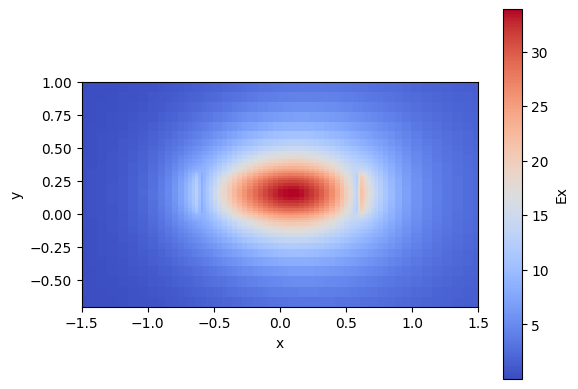

In [187]:
bend_1550 = gt.modes.Waveguide(
    wavelength=1550 * nm,
    core_width=1.2,
    slab_thickness=0.0,
    core_material='sin',
    clad_material='sio2',
    core_thickness=300 * nm,
    num_modes=1,
    cache_path='.cache/',
    precision='double',
    max_grid_scaling=1.2,
    grid_resolution=20, 
    bend_radius=20, # Bend radius
)

bend_1550.plot_field(field_name="Ex", 
                     mode_index=0, # Field to be plotted
                     value='abs', # Real - abs - imag
                     cmap='coolwarm',
                     xlim=(-1.5, 1.5), # Set the x and y limits
                     ylim=(-0.7, 1)) 

### Mode-mismatch loss

Bend waveguide mode differs slightly from the straight waveguide mode, wich yield into mode-convertion losses. We can calculate this factor with as the overlap of the latter two modes. 

This is already implemented on GDSfactory library: 

  0%|          | 0/10 [00:00<?, ?it/s]

c:\Users\cfp\Desktop\David\Diseño\LAB\Sesion4\pic-upv-lab1\.venv\Lib\site-packages\tidy3d\components\mode\derivatives.py:14: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  dxf = sp.csr_matrix(sp.diags([-1, 1], [0, 1], shape=(Nx, Nx)))
c:\Users\cfp\Desktop\David\Diseño\LAB\Sesion4\pic-upv-lab1\.venv\Lib\site-packages\tidy3d\components\mode\derivatives.py:27: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  dxb = sp.csr_matrix(sp.diags([1, -1], [0, -1], shape=(Nx, Nx)))
c:\Users\cfp\Desktop\David\Diseño\LAB\Sesion4\p

Text(0, 0.5, 'Mismatch (dB)')

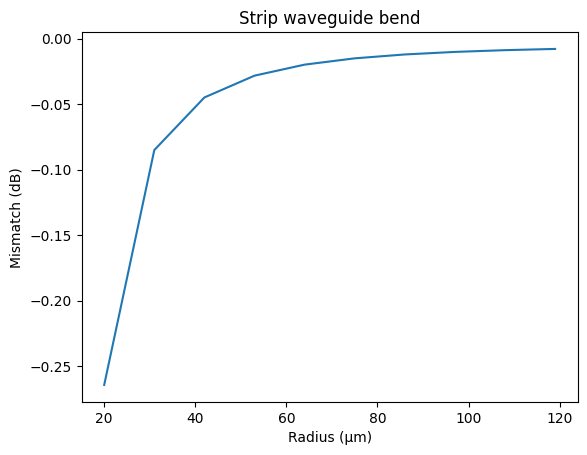

In [188]:
radii = np.arange(20.0, 120,11)

mismatch = gt.modes.sweep_bend_mismatch(bend_1550, radii)

plt.plot(radii, 10 * np.log10(mismatch))
plt.title("Strip waveguide bend")
plt.xlabel("Radius (μm)")
plt.ylabel("Mismatch (dB)")

With 120 micras no losses more or less. We have 0.3 db losses for each 20 micra radio. if i wanto to have a spiral with a lot of turns, with 20 micras its not feasible. A LOT OF LOSSES
But we not only have the losses of making the bend, we have that larger the radia, larger the perimeter of a circle. For a 120 microns of radia, we increasing the path lenght of the light, more footprint and more propagation losses

### Propagation loss

Consider the equivalent linear length of the quarter-circle bend. Light will attenuate following a trend quantified with the experimentally measured parameter $$\alpha [\mathrm{dB}/\mathrm{cm}]$$. It depends on the fabrication process mainly. We will add this loss (in dBs) to the mode-mismatch loss to calculate the total loss per bend. 

*We are not considering the radiation losses, mainly because is not easy to implement a quick simulation for this parameter. Under certain conditions, the main loss sources are the ones considered in this example


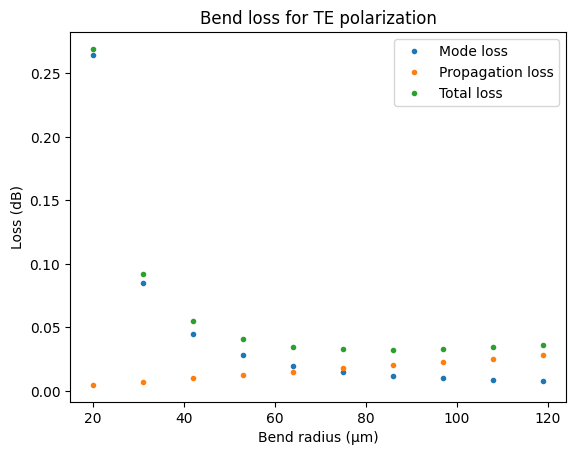

In [229]:
dB_cm = 1.5  # dB/cm Technology loss - 
length = 0.5 * np.pi * radii * 1e-6 #quarter circle perimeter in fucntion radius
propagation_loss = dB_cm * length * 1e2 #Microns to centimeters
propagation_loss

plt.title("Bend loss for TE polarization")
plt.plot(radii, -10 * np.log10(mismatch), ".", label="Mode loss")
plt.plot(radii, propagation_loss, ".", label="Propagation loss")
plt.plot(radii, propagation_loss-10 * np.log10(mismatch), ".", label="Total loss")
plt.xlabel("Bend radius (μm)")
plt.ylabel("Loss (dB)")
plt.legend()

- Use the code provided in this section to calculate the safe radius for 1.2 um width deep waveguides at 1.5 um. 

## EXTRA

All the past simulations were done considering as core material de Silicon Nitride (SiNx) and Silicon Dioxide (SiO2) as cladding material. Now, **simulate the Silicon-On-Insulator technology changing the core material to Silicon (Si)**. In this case, the dimensions will be 220 nm heigth and 500 nm width. 
1. Repeat the LO.1. wavelength behavior simulations, considering the updated materials and dimensions. 
2. Repeat the LO.3. width dependence analysis, now sweeping in a 300nm - 1um range. 
3. Find the safe radius for this technology. Consider sweeping the radius in a 5um to 30um range. 
4. **Compare the SiNx and SOI technologies** 

## Grading

LO.1. 2 Point <br> 
LO.2. 1 Points <br> 
LO.3. 3 Point <br> 
LO.4. 1 Points <br> 
**Total 7 Points** <br>
Extra (Up to) 3 Points
